In [15]:
import sympy as sp

In [16]:
R1, R2, N = sp.symbols('R1 R2 N', positive=True)
i1, r1, K1, h, e, r2, K2, i2, B, D, z, w, C1, C2 = sp.symbols(
    'i1 r1 K1 h e r2 K2 i2 B D z w C1 C2', positive=True)
c1 = C1 * z**w
c2 = C2 *(1 - z)**w
f1 = c1 /(1 + h * c1 * R1 + e * h * c2 * R2)
f2 = c2 /(1 + h * c1 * R1 + e * h * c2 * R2)
intake = (f1 * R1 + e * f2 * R2) 
dR1dt = i1 + r1 * R1 *(1 - R1/K1) - f1 * R1 * N
dR2dt = i2 + r2 * R2 *(1 - R2/K2) - f2 * R2 * N
dNdt = N * (B * intake - D)

In [17]:
sp.diff(intake, z).simplify()

w*(C1*R1*z**(w + 1)*(z - 1)**2*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1) - C2*R2*e*z**2*(1 - z)**(w + 1)*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1) - h*z*(z - 1)*(C1*R1*z**w + C2*R2*e*(1 - z)**w)*(C1*R1*z**w*(z - 1) + C2*R2*e*z*(1 - z)**w))/(z**2*(z - 1)**2*(C1*R1*h*z**w + C2*R2*e*h*(1 - z)**w + 1)**2)

In [17]:
dintakedz_simp = R1*sp.diff(c1, z) + e*R2*sp.diff(c2, z)
dintakedz_simp.simplify()

w*(C1*R1*z**w*(z - 1) + C2*R2*e*z*(1 - z)**w)/(z*(z - 1))

In [25]:
numer = sp.numer(sp.together(dintakedz_simp))/w
numer

C1*R1*z**w*(1 - z) - C2*R2*e*z*(1 - z)**w

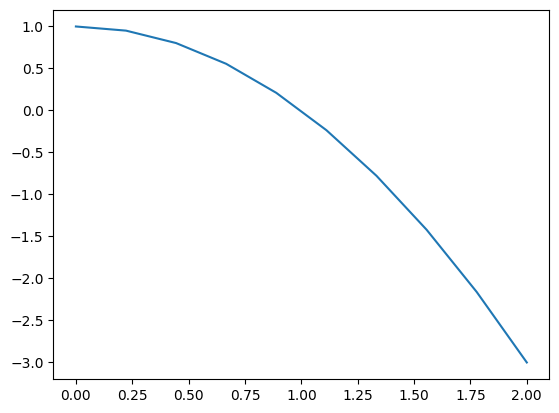

In [1]:
def tradeoff(w, c1):
    return 1 - c1**(1/w)

import matplotlib.pyplot as plt
import numpy as np
plt.plot(np.linspace(0, 2, 10), tradeoff(0.5, np.linspace(0, 2, 10)))

In [1]:
def system_switching(t, vars, cg):
    R1, R2, N = vars
    u = 1/(1-cg.w)
    zopt = (cg.C1 * R1)**u/((cg.e * cg.C2 * R2)**u + (cg.C1 * R1)**u)
    c1 = cg.C1 * zopt**cg.w
    c2 = cg.C2 *(1 - zopt)**cg.w
    f1 = c1 /(1 + cg.h * c1 * R1 + cg.e * cg.h * c2 * R2)
    f2 = c2 /(1 + cg.h * c1 * R1 + cg.e * cg.h * c2 * R2)
    intake = (f1 * R1 + cg.e * f2 * R2) 
    dR1dt = cg.i1 + cg.r1 * R1 *(1 - R1/cg.K1) - f1 * R1 * N
    dR2dt = cg.i2 + cg.r2 * R2 *(1 - R2/cg.K2) - f2 * R2 * N
    dNdt = N * (cg.B * intake - cg.D)
    return [dR1dt, dR2dt, dNdt]

In [2]:
from tools import Config
import numpy as np
from scipy.integrate import solve_ivp

In [3]:
pars = Config(dict(C1 = 5, C2 = 5, h = 1, B = 0.1, K1 = 1, K2 = 1, i1 = 0, i2 = 0, r1 = 1, r2 = 0.25, D = 0.05, e = 1, w = 0.8))
system_switching(0, [1, 1, 1], pars)

[-0.4258544361461612, -0.4258544361461612, 0.03517088722923224]

In [12]:
init = [0.1, 0.1, 0.1]
sol = solve_ivp(lambda t, y: system_switching(t, y, pars), t_span = [0, 1000], y0 =init, t_eval = np.linspace(0, 1000, 6000))

/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_71655/3100993672.py:4: RuntimeWarning: invalid value encountered in scalar power
  zopt = (cg.C1 * R1)**u/((cg.e * cg.C2 * R2)**u + (cg.C1 * R1)**u)


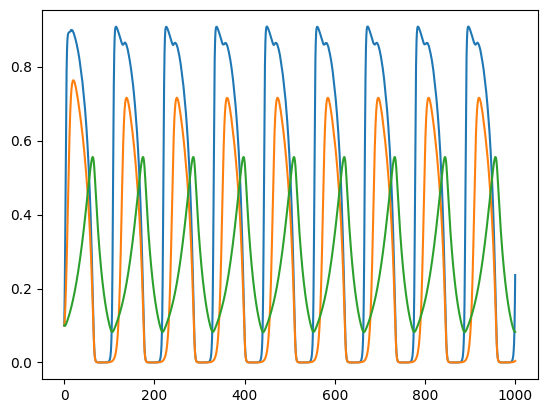

In [13]:
import matplotlib.pylab as plt
plt.plot(sol.t, sol.y[0], label = 'R1')
plt.plot(sol.t, sol.y[1], label = 'R2')
plt.plot(sol.t, sol.y[2], label = 'N')